# Init

In [26]:
import sys
import os
sys.path.insert(1, '../..')

In [27]:
import pandas as pd

# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path, index_col=0)


In [28]:
display(df.head())
display(df.describe())

,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,sby_used_percent,personal_calculated_by_calls,...,month,day_of_week,day_of_month,week_of_year,day_of_year,is_weekend,is_holiday,tavg,tmin,tmax
date,,,,,,,,,,,,,,,,,,,,,
2016-04-01,73,8154.0,1700,90,4.0,0.0,1459468800,1704.0,0.044444,1734.893617,...,4,4,1,13,92,False,False,8.3,5.0,13.1
2016-04-02,64,8526.0,1700,90,70.0,0.0,1459555200,1770.0,0.777778,1814.042553,...,4,5,2,13,93,True,False,9.9,1.3,16.4
2016-04-03,68,8088.0,1700,90,0.0,0.0,1459641600,1700.0,0.000000,1720.851064,...,4,6,3,13,94,True,False,13.1,6.1,19.1
2016-04-04,71,7044.0,1700,90,0.0,0.0,1459728000,1700.0,0.000000,1498.723404,...,4,0,4,14,95,False,False,15.2,9.5,20.6
2016-04-05,63,7236.0,1700,90,0.0,0.0,1459814400,1700.0,0.000000,1539.574468,...,4,1,5,14,96,False,False,16.0,8.4,22.7


,n_sick,calls,n_duty,n_sby,sby_need,dafted,unix_ts_date,needed_personal,sby_used_percent,personal_calculated_by_calls,...,call_stress,year,month,day_of_week,day_of_month,week_of_year,day_of_year,tavg,tmin,tmax
count,1152.000000,1152.000000,1152.000000,1152.0,1152.000000,1152.000000,1.152000e+03,1152.000000,1152.000000,1152.000000,...,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000,1152.000000
mean,68.808160,7919.531250,1833.333333,90.0,30.182292,16.335938,1.509192e+09,1863.515625,0.335359,1685.006649,...,4.238179,2017.333333,6.424479,3.002604,15.674479,26.023438,180.072049,11.268229,7.051997,15.467882
std,14.293942,1290.063571,97.759435,0.0,71.753595,53.394089,2.874511e+07,124.273086,0.797262,274.481611,...,0.541139,0.977594,3.394101,2.002386,8.778030,14.770423,103.880984,7.711124,6.679351,9.095201
min,36.000000,4074.000000,1700.000000,90.0,0.000000,0.000000,1.459469e+09,1700.000000,0.000000,866.808511,...,2.263333,2016.000000,1.000000,0.000000,1.000000,1.000000,1.000000,-8.800000,-12.800000,-5.800000
25%,58.000000,6978.000000,1800.000000,90.0,0.000000,0.000000,1.484330e+09,1800.000000,0.000000,1484.680851,...,3.860882,2017.000000,4.000000,1.000000,8.000000,14.000000,95.000000,5.200000,1.900000,7.900000
50%,68.000000,7932.000000,1800.000000,90.0,0.000000,0.000000,1.509192e+09,1874.500000,0.000000,1687.659574,...,4.323158,2017.000000,6.000000,3.000000,16.000000,25.000000,174.000000,10.600000,6.700000,14.950000
75%,78.000000,8827.500000,1900.000000,90.0,0.000000,0.000000,1.534054e+09,1905.250000,0.000000,1878.191489,...,4.765372,2018.000000,9.000000,5.000000,23.000000,39.000000,270.000000,17.800000,12.400000,23.000000
max,119.000000,11850.000000,2000.000000,90.0,461.000000,465.000000,1.558915e+09,2455.000000,5.122222,2521.276596,...,4.896288,2019.000000,12.000000,6.000000,31.000000,52.000000,366.000000,28.900000,23.900000,38.000000


In [29]:
def calculate_custom_personal_metrics(df: pd.DataFrame, orig_column : str , pred_column : str, print_results: bool = False) -> dict:

    df = df.copy(deep=True)

    # Berechnung der Unterbesetzung und Überbesetzung
    df['understaffed'] = df[orig_column] > df[pred_column]
    df['overstaffed'] = df[orig_column] < df[pred_column]
    df['perfect'] = df[orig_column] == df[pred_column]
    
    # Anteil an Tagen mit Unterbesetzung
    total_days = len(df)
    understaffed_days = df['understaffed'].sum()
    overstaffed_days = df['overstaffed'].sum()
    perfect_days = df['perfect'].sum()
    
    # Durchschnittliche Über- und Unterbesetzung
    avg_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].mean()
    avg_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].mean()
    median_understaffing = (df[orig_column] - df[pred_column])[df['understaffed']].median()
    median_overstaffing = (df[pred_column] - df[orig_column])[df['overstaffed']].median()

    # Tagesdurchschnitt Ersatzfahrer für pred_column über die ganze Zeit
    avg_replacement_drivers_pred = df[pred_column].mean()
    
    # Differenz Tagesdurchschnitt Ersatzfahrer für pred_column zu Summe bei orig
    avg_replacement_drivers_orig = df[orig_column].mean()
    difference_avg_replacement_drivers = (avg_replacement_drivers_pred - avg_replacement_drivers_orig).mean()

    results = {
        'Anteil an Tagen mit Unterbesetzung (%)': understaffed_days / total_days * 100,
        'Anteil an Tagen mit Überbesetzung (%)': overstaffed_days / total_days * 100,
        'Anteil an Tagen mit perfekter Prediction (%)': perfect_days / total_days * 100,
        'Durchschnittliche Überbesetzung': avg_overstaffing,
        'Durchschnittliche Unterbesetzung': avg_understaffing,
        'Median Überbesetzung': median_overstaffing,
        'Median Unterbesetzung': median_understaffing,
        'Tagesdurchschnitt Ersatzfahrer für Planung': avg_replacement_drivers_pred,
        'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': difference_avg_replacement_drivers
    }

    if print_results:
        print(f'Results: - ' + ', '.join(f'{key}: {value}' for key, value in results.items()))

    return results


display("Aktueller Stand der Metriken mit festem n_sby:")
display(calculate_custom_personal_metrics(df, "sby_need", "n_sby", print_results=False))

display("Stand, wenn man dynamisch aus Calls berechnet:")
display(calculate_custom_personal_metrics(df, "sby_need", "sby_need_calculated_by_calls", print_results=False))

'Aktueller Stand der Metriken mit festem n_sby:'

{'Anteil an Tagen mit Unterbesetzung (%)': 13.10763888888889,
 'Anteil an Tagen mit Überbesetzung (%)': 86.63194444444444,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.26041666666666663,
 'Durchschnittliche Überbesetzung': 84.44689378757515,
 'Durchschnittliche Unterbesetzung': 101.7748344370861,
 'Median Überbesetzung': 90.0,
 'Median Unterbesetzung': 85.0,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 90.0,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 59.81770833333333}

'Stand, wenn man dynamisch aus Calls berechnet:'

{'Anteil an Tagen mit Unterbesetzung (%)': 0.08680555555555555,
 'Anteil an Tagen mit Überbesetzung (%)': 30.46875,
 'Anteil an Tagen mit perfekter Prediction (%)': 69.44444444444444,
 'Durchschnittliche Überbesetzung': 46.2178577923258,
 'Durchschnittliche Unterbesetzung': 0.1276595744682254,
 'Median Überbesetzung': 50.085106382978694,
 'Median Unterbesetzung': 0.1276595744682254,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 44.2641843971631,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 14.081892730496431}

# Baseline Model

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

target_column_name = "sby_need"

train_size = int(len(df) * 0.8)
train, test = df.iloc[:train_size], df.iloc[train_size:]

# Baseline-Modell: Durchschnitt der Zielvariable im Trainingsset
baseline_pred = train[target_column_name].mean()

test = test.copy()

test['baseline_pred'] = baseline_pred


$R^2=-0.00$
$MAE=48.46$
$RMSE=75.87$


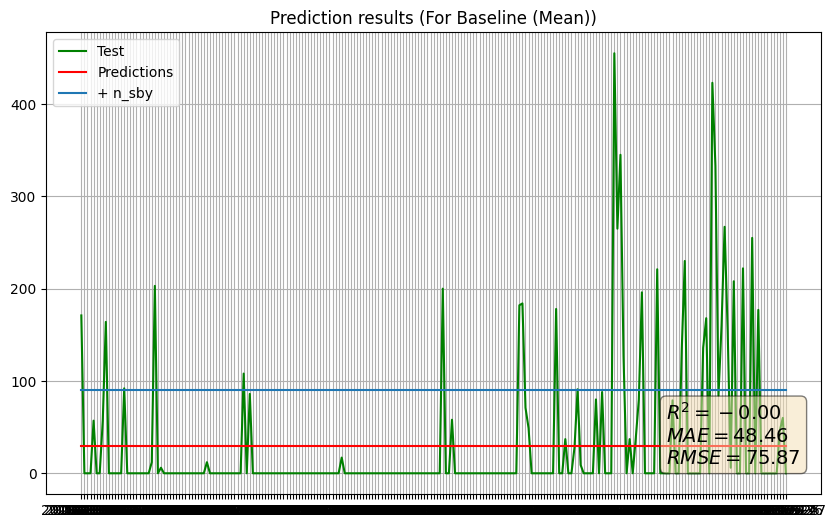

{'Anteil an Tagen mit Unterbesetzung (%)': 19.480519480519483,
 'Anteil an Tagen mit Überbesetzung (%)': 80.51948051948052,
 'Anteil an Tagen mit perfekter Prediction (%)': 0.0,
 'Durchschnittliche Überbesetzung': 29.51070015060768,
 'Durchschnittliche Unterbesetzung': 126.7832066594281,
 'Median Überbesetzung': 29.99457111834962,
 'Median Unterbesetzung': 124.00542888165037,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 29.994571118349608,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': -0.9361648123863233}

In [31]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, root_mean_squared_error
import matplotlib.pyplot as plt

def plot_regression_predictions(y_true: pd.DataFrame, y_pred: pd.DataFrame, y_train: pd.DataFrame = None, annotation : str = "", additional_column_df : pd.DataFrame = None) -> None:
    
    # Metrics
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)

    mape = mean_absolute_percentage_error(y_true, y_pred)

    # Plot 
    plt.figure(figsize=(10, 6))
    plt.title(f'Prediction results' + (f" ({annotation})" if annotation else ""))

    if y_train is not None:
        plt.plot(y_train.index, y_train, label='Train', color='blue')

    plt.plot(y_true.index, y_true, label='Test', color='green')
    plt.plot(y_true.index, y_pred, label='Predictions', color='red')

    if additional_column_df is not None:

        max_value = max([
        y_true.select_dtypes(include=[float, int]).max().max(),
        y_pred.select_dtypes(include=[float, int]).max().max(),
        additional_column_df.select_dtypes(include=[float, int]).max().max(),
        ])

        for column in additional_column_df.columns:
            if additional_column_df[column].dtype == bool:
                plt.plot(additional_column_df.index, additional_column_df[column].astype(int) * max_value, label =  "+ " +column + " (bool)", linestyle="dotted")
            else:
                plt.plot(additional_column_df.index, additional_column_df[column], label = "+ " + column)

    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)

    textstr = '\n'.join((
        r'$R^2=%.2f$' % (r2, ),
        r'$MAE=%.2f$' % (mae, ),
        r'$RMSE=%.2f$' % (rmse, )))

    print(textstr)

    plt.text(0.8, 0.2, textstr, transform=plt.gca().transAxes, fontsize=14,
        verticalalignment='top', bbox=props)

    plt.legend()
    plt.grid()
    plt.show()


plot_regression_predictions(test[[target_column_name]], test[["baseline_pred"]],  additional_column_df=test[["n_sby"]], annotation="For Baseline (Mean)")

display(calculate_custom_personal_metrics(test, "sby_need", "baseline_pred"))

# Modeling

In [32]:
target_column_name = 'calls' #'sby_need'

usable_columns = ["day_of_week", "day_of_month", "day_of_year", "year"]

In [33]:
from sklearn.model_selection import train_test_split


# Prepare features and target
X = df[usable_columns]
y = df[target_column_name]

# Split data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False) # shuffle = False -> to keep the order of data

In [34]:

# Models used in comparision
from sklearn.ensemble import StackingRegressor, RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.ensemble import BaggingRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C

# Additional models, which are not from sklearn
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Own classes
from app.sklearn_keras_wrapper import LSTMModelWrapper, GRUModelWrapper, CNNModelWrapper, TDNNModelWrapper, TransformerModelWrapper

shared_regularization_for_underestimation = 50

models = {

    "LSTM" : LSTMModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=shared_regularization_for_underestimation),
    "GRU" : GRUModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=shared_regularization_for_underestimation),
    "CNN" : CNNModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=shared_regularization_for_underestimation),
    "TDNN" : TDNNModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=shared_regularization_for_underestimation),
    "Transformer" : TransformerModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=shared_regularization_for_underestimation),

    'Linear Regression': LinearRegression(),
    
    'Decision Tree': DecisionTreeRegressor(),
    
    'Random Forest': RandomForestRegressor(
        #n_estimators=200, 
        #max_depth=10, 
        #min_samples_split=10, 
        #min_samples_leaf=5, 
        #bootstrap=True, 
        #random_state=42, 
        #n_jobs=-1
    ),
    
    'Gradient Boosting': GradientBoostingRegressor(
        #n_estimators=200, 
        #learning_rate=0.05, 
        #max_depth=4, 
        #subsample=0.8, 
        #random_state=42
    ),
    
    'Lasso Regression': Lasso(
        alpha=0.01, 
        max_iter=1000, 
        random_state=42
    ),
    
    'Ridge Regression': Ridge(
        alpha=1.0, 
        random_state=42
    ),
    
    'XGBoost': XGBRegressor(
        #n_estimators=200, 
        #learning_rate=0.05, 
        #max_depth=4, 
        #subsample=0.8, 
        #colsample_bytree=0.8, 
        #random_state=42, 
        #n_jobs=-1
    ),
    
    # # Polynomial Regression
    # 'Polynomial Regression (8)': Pipeline([
    #     ('poly', PolynomialFeatures(degree=8)),
    #     ('linear', LinearRegression())
    # ]),
    
    # 'Polynomial Ridge Regression (8)': Pipeline([
    #     ('poly', PolynomialFeatures(degree=8)),
    #     ('ridge', Ridge(alpha=1.0))
    # ]),
    'LightGBM': LGBMRegressor(random_state=42),
    # 'Bagging Regressor': BaggingRegressor(
    #     n_estimators=50,
    #     random_state=42,
    #     n_jobs=-1
    # ),
    
    # 'HistGradient Boosting': HistGradientBoostingRegressor(
    #     loss='absolute_error',
    #     learning_rate=0.05,
    #     max_iter=100,
    #     max_depth=4,
    #     random_state=42
    # )
}


## Comparision

In [35]:
import numpy as np
import time
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from sklearn.preprocessing import MinMaxScaler


def compare_regression_models(models, X_train, y_train, X_test, y_test, print_results : bool = False, sorted_by = "R2", sorted_asc=False, custom_metric_func=None):

    # Train and evaluate each model
    results = {}

    for model_name, model in models.items():

        start_time = time.time()
        model.fit(X_train, y_train)
        end_time = time.time() 

        start_time_pred = time.time()
        y_pred = model.predict(X_test)
        end_time_pred = time.time() 

        results[model_name] = {
            "MAE" : mean_absolute_error(y_test, y_pred),
            "MSE" : mean_squared_error(y_test, y_pred),
            "RMSE" : np.sqrt(mean_squared_error(y_test, y_pred)),
            "R2" : r2_score(y_test, y_pred),
            "MAPE" : mean_absolute_percentage_error(y_test, y_pred),
            "Training time (s)" : end_time - start_time,
            "Prediction time (s)" : end_time_pred - start_time_pred,
        }

        # Custom metrics
        if custom_metric_func:
            custom_metrics = custom_metric_func(y_test, y_pred)
            results[model_name].update(custom_metrics)
        
        if print_results:
            print(f'{model_name} - ' + ', '.join(f'{key}: {value}' for key, value in results[model_name].items()))


    results_df = pd.DataFrame(results).T

    results_df_sorted = results_df.sort_values(by=sorted_by, ascending=sorted_asc)

    return results_df_sorted

#######

# Wrapper for calculate_custom_personal_metrics in order to us it in comparision
def custom_metrics_for_pred(y_true, y_pred):

    result_df = df.loc[y_true.index, ["n_duty", "sby_need", "n_sby", "calls"]]

    if target_column_name == "calls":

        result_df["predicted_calls" ] = y_pred

        result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.7) - row.n_duty) , axis=1)
    
        return calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc", print_results=False)

    elif target_column_name == "sby_need":
        result_df["predicted_sby_need" ] = y_pred
        return calculate_custom_personal_metrics(result_df, "sby_need", "predicted_sby_need", print_results=False)
    
    else:
        print("Custom metrics cant be calculated for this column:", target_column_name)
        return {}

#results_df_sorted = compare_regression_models(models, X_train, y_train, X_test, y_test, custom_metric_func=custom_metrics_for_pred, sorted_by="R2", sorted_asc=False)
results_df_sorted = compare_regression_models(models, X_train, y_train, X_test, y_test, custom_metric_func=custom_metrics_for_pred, sorted_by="Anteil an Tagen mit Unterbesetzung (%)", sorted_asc=True)

display(results_df_sorted)

Epoch 1/50


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 42ms/step - loss: 3.3492 - val_loss: 0.0804
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.1592 - val_loss: 0.0869
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.1194 - val_loss: 0.0949
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.1003 - val_loss: 0.1009
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.1006 - val_loss: 0.1789
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0976 - val_loss: 0.1124
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step - loss: 0.0893 - val_loss: 0.0675
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0815 - val_loss: 0.0900
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0875 - val_loss: 0.1028
Epoch 10/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0816 - val_loss: 0.1036
Epoch 11/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0896 - val_loss: 0.0877
Epoch 12/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0747 - val_l

/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - loss: 1.6442 - val_loss: 0.1065
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.2634 - val_loss: 0.0917
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1632 - val_loss: 0.0753
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1224 - val_loss: 0.0619
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1054 - val_loss: 0.0554
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0979 - val_loss: 0.1109
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0884 - val_loss: 0.0543
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0928 - val_loss: 0.0706
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0865 - val_loss: 0.1971
Epoch 10/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0880 - val_loss: 0.1169
Epoch 11/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0856 - val_loss: 0.0524
Epoch 12/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0818 - val_l

/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 2.3282 - val_loss: 0.1513
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1934 - val_loss: 0.1919
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1275 - val_loss: 0.0958
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1201 - val_loss: 0.1910
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1074 - val_loss: 0.1833
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0871 - val_loss: 0.7992
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0985 - val_loss: 0.5126
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0812 - val_loss: 0.3444
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0977 - val_loss: 0.1691
Epoch 10/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0900 - val_loss: 0.3238
Epoch 11/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0766 - val_loss: 0.2595
Epoch 12/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0832 - val_loss: 0.1291


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.6746 - val_loss: 0.0726
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.2936 - val_loss: 0.1016
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1755 - val_loss: 0.0839
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1864 - val_loss: 0.0696
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1716 - val_loss: 0.1673
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1798 - val_loss: 0.0780
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1398 - val_loss: 0.0851
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1617 - val_loss: 0.0647
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1238 - val_loss: 0.0731
Epoch 10/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1342 - val_loss: 0.1045
Epoch 11/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1127 - val_loss: 0.1078
Epoch 12/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.1320 - val_loss: 0.0809


,MAE,MSE,RMSE,R2,MAPE,Training time (s),Prediction time (s),Anteil an Tagen mit Unterbesetzung (%),Anteil an Tagen mit Überbesetzung (%),Anteil an Tagen mit perfekter Prediction (%),Durchschnittliche Überbesetzung,Durchschnittliche Unterbesetzung,Median Überbesetzung,Median Unterbesetzung,Tagesdurchschnitt Ersatzfahrer für Planung,Differenz Tagesdurchschnitt Ersatzfahrer zu Realität
LSTM,1434.743290,3.049516e+06,1746.286457,-0.818169,0.188815,22.942591,0.748549,2.164502,78.354978,19.480519,154.187457,25.682325,152.859685,15.074353,151.188390,120.257654
GRU,1466.511659,3.164692e+06,1778.958104,-0.886838,0.192943,22.546999,1.308911,2.597403,81.385281,16.017316,156.012113,47.795110,155.894839,35.597445,156.660201,125.729465
TDNN,1309.117265,2.517710e+06,1586.729302,-0.501098,0.171276,3.170628,0.100339,5.194805,66.666667,28.138528,141.994182,87.576848,131.420526,73.974175,121.044077,90.113341
CNN,1533.939650,3.374678e+06,1837.029676,-1.012035,0.203346,2.162171,0.125311,7.792208,92.207792,0.000000,126.945037,70.913453,131.531830,40.870347,142.458228,111.527492
Transformer,1746.545238,4.268051e+06,2065.926271,-1.544678,0.231352,21.030557,0.305418,8.658009,91.341991,0.000000,174.857099,93.598914,148.820155,65.733742,182.544890,151.614154
Decision Tree,1261.480519,2.435352e+06,1560.561587,-0.451995,0.146316,0.003754,0.000832,19.047619,10.822511,70.129870,151.670638,135.042553,144.680851,99.500000,21.622916,-9.307820
Linear Regression,977.281052,1.366125e+06,1168.813406,0.185495,0.123135,0.001296,0.000565,20.779221,10.389610,68.831169,38.328049,134.703617,27.059491,121.211529,6.922509,-24.008227
Lasso Regression,977.277885,1.366112e+06,1168.808035,0.185503,0.123135,0.001253,0.000509,20.779221,10.389610,68.831169,38.320656,134.705730,27.051563,121.215688,6.921302,-24.009434
Ridge Regression,977.076292,1.365311e+06,1168.465331,0.185980,0.123083,0.001112,0.000510,20.779221,10.389610,68.831169,37.912117,134.826801,26.615609,121.460363,6.853699,-24.077037
XGBoost,1111.588546,1.866803e+06,1366.309986,-0.113017,0.127091,0.037766,0.002736,20.779221,3.030303,76.190476,33.904232,129.936805,32.621551,91.500000,4.958281,-25.972455


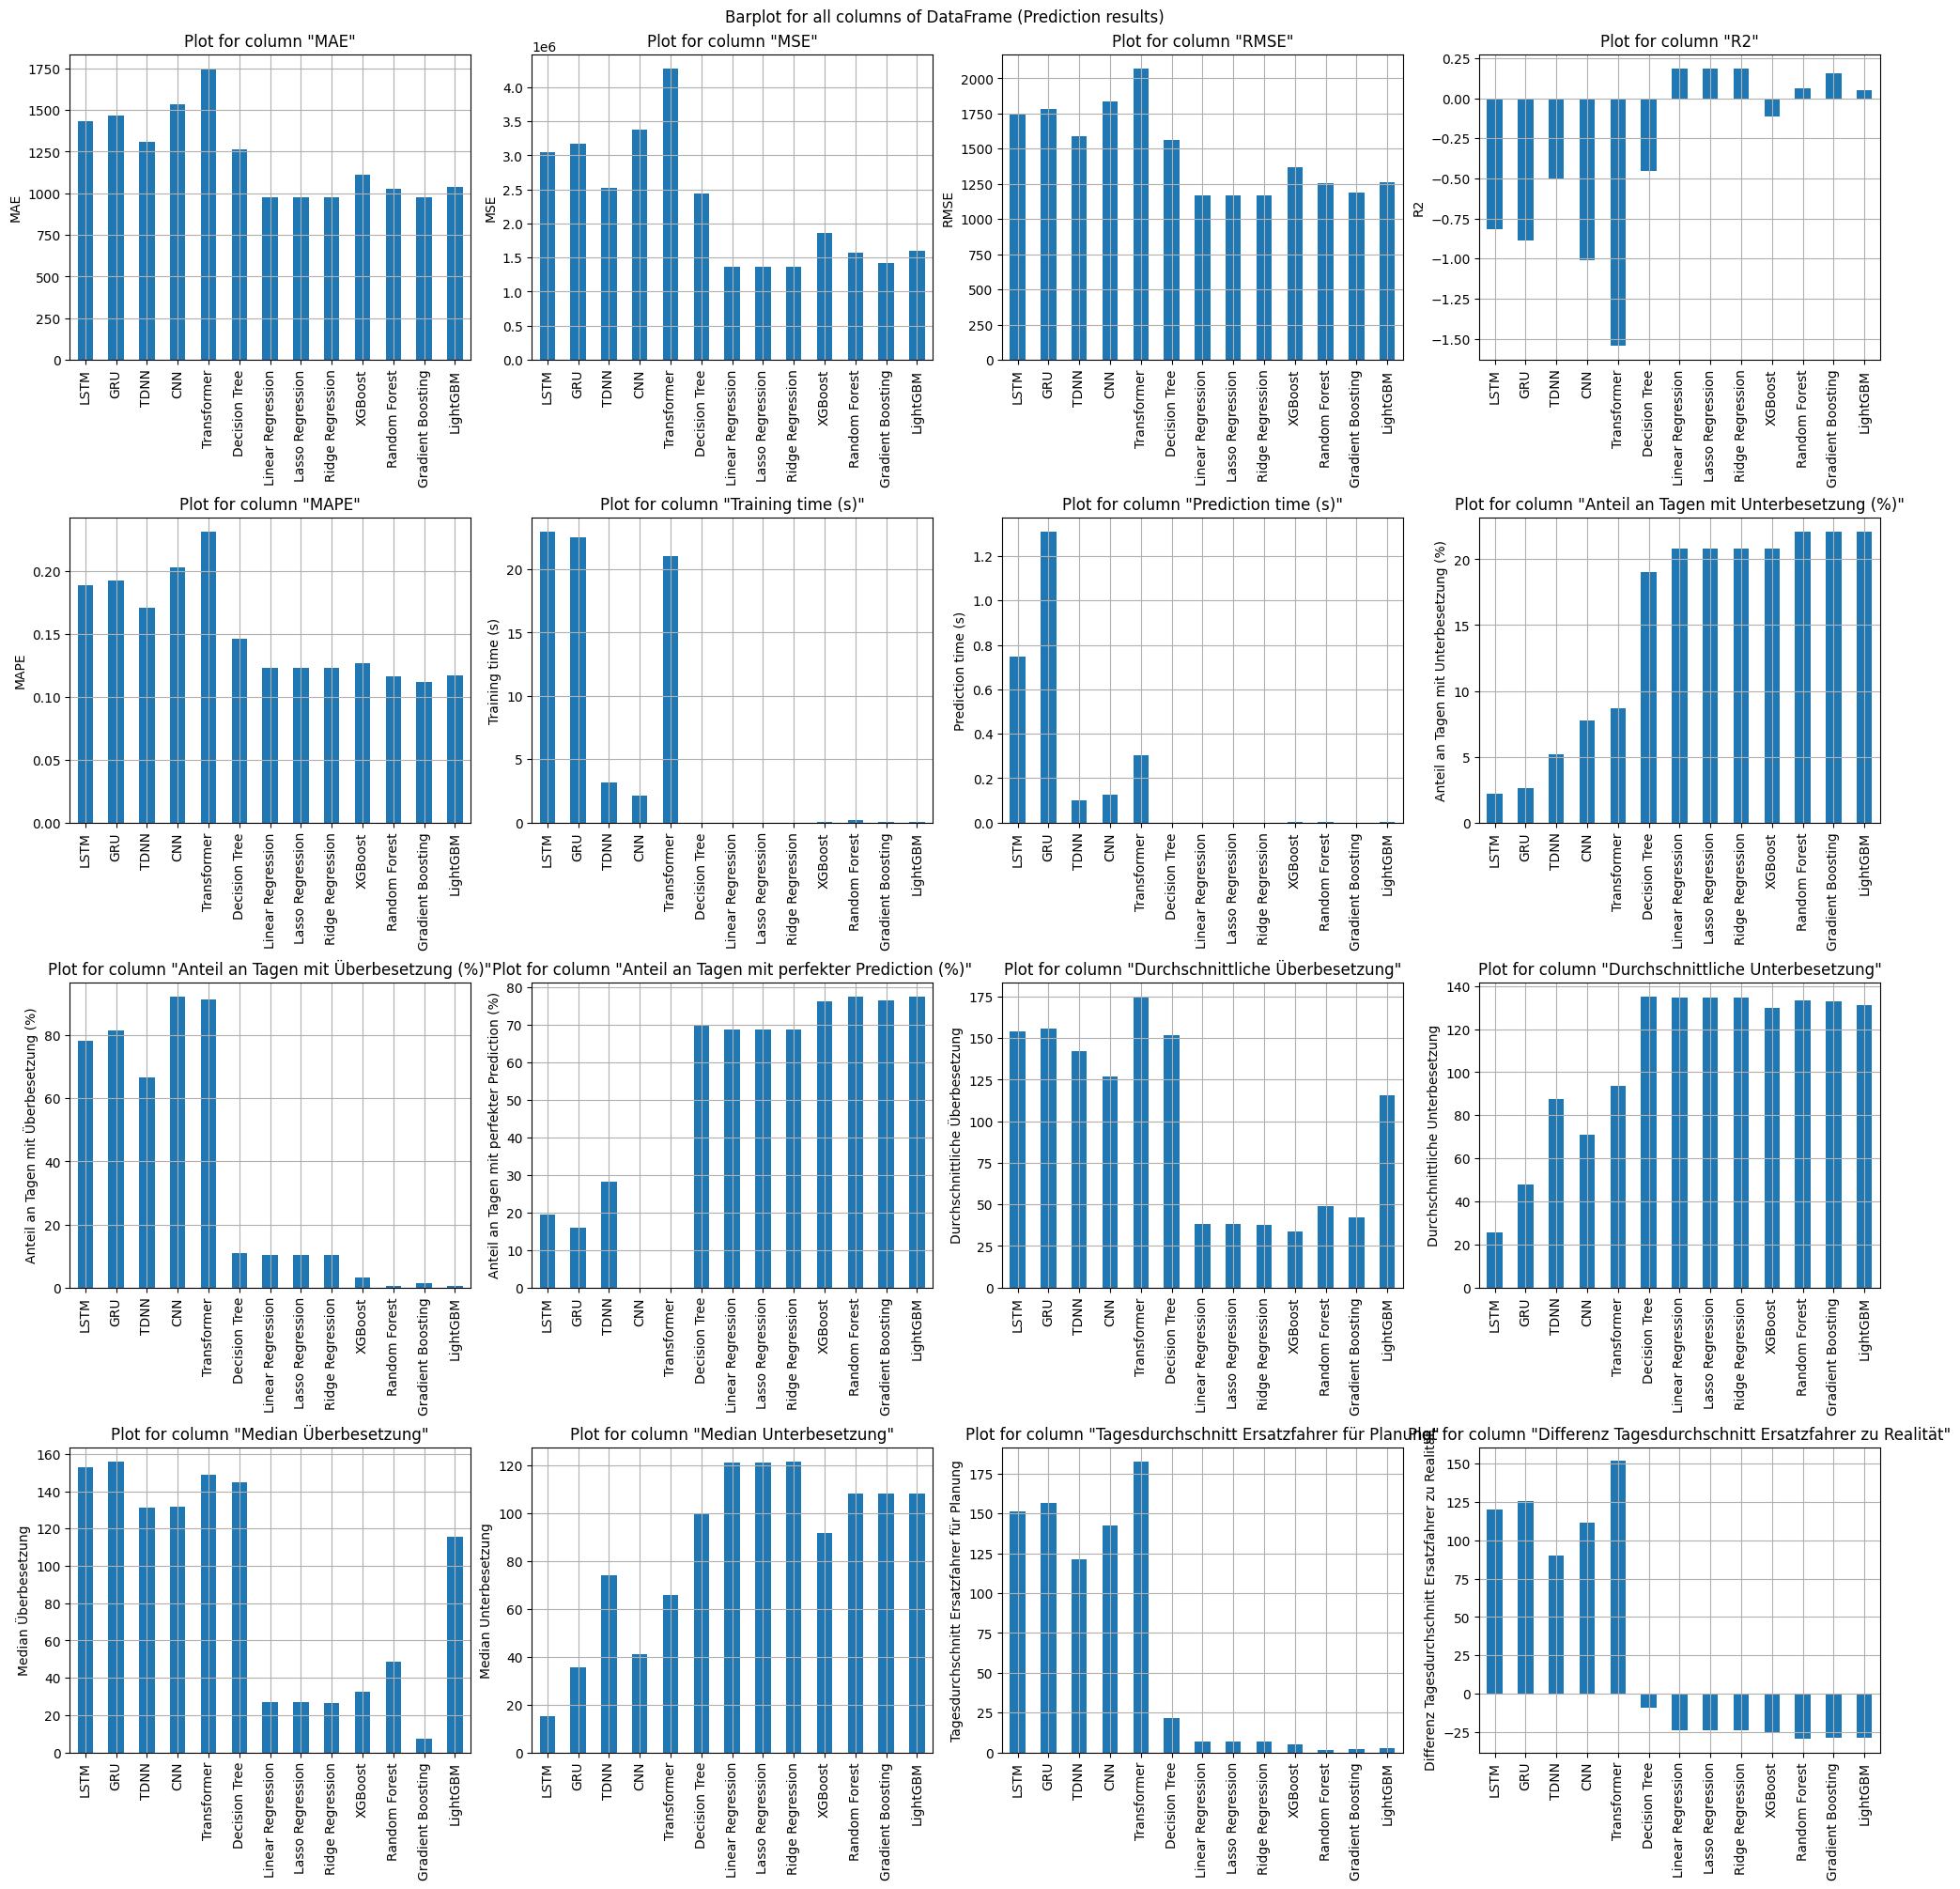

In [36]:
import matplotlib.pyplot as plt

import math
from typing import List, Optional

def barplot_columns_in_subplots(df : pd.DataFrame, columns: Optional[List[str]] = None, annotation: str = "") -> None:

    if columns is None:
        columns = df.columns

    # number of columns in datafram
    num_columns = len(columns)

    # number of rows and columns for the subplots
    if num_columns > 2:
        num_rows = math.ceil(math.sqrt(num_columns))
        num_cols = math.ceil(num_columns / num_rows)
    else:
        num_rows = 1
        num_cols = num_columns

    # Create subplots
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(20, 20), constrained_layout=True)
    fig.suptitle(f'Barplot for all columns of DataFrame' + (f" ({annotation})" if annotation else ""), fontsize=12)

    # Plots für jede Spalte erstellen
    for i, column in enumerate(columns):
        if num_columns > 2:
            row = i // num_cols
            col = i % num_cols
            ax = axes[row, col]
        else:
            ax = axes[i] if num_columns > 1 else axes
        if df[column].dtype == bool:
            df[column].astype(int).plot(kind='bar', ax=ax, title=f'Plot for column "{column}" (bool)')
        else:
            df[column].plot(kind='bar', ax=ax, title=f'Plot for column "{column}"')
        ax.set_xlabel(df.index.name)
        ax.set_ylabel(column)
        ax.grid()

    # Remove empty Subplots
    for j in range(i + 1, num_rows * num_cols):
        fig.delaxes(axes.flatten()[j])

    plt.show()

####

barplot_columns_in_subplots(results_df_sorted, annotation="Prediction results")


In [37]:
# Select the best model
best_model_name = results_df_sorted.index[0]
best_model_results = results_df_sorted.loc[best_model_name]

best_model = models[best_model_name]

print(f'Best Model: {best_model_name}')
print(best_model_results)

Best Model: LSTM
MAE                                                     1.434743e+03
MSE                                                     3.049516e+06
RMSE                                                    1.746286e+03
R2                                                     -8.181689e-01
MAPE                                                    1.888154e-01
Training time (s)                                       2.294259e+01
Prediction time (s)                                     7.485495e-01
Anteil an Tagen mit Unterbesetzung (%)                  2.164502e+00
Anteil an Tagen mit Überbesetzung (%)                   7.835498e+01
Anteil an Tagen mit perfekter Prediction (%)            1.948052e+01
Durchschnittliche Überbesetzung                         1.541875e+02
Durchschnittliche Unterbesetzung                        2.568232e+01
Median Überbesetzung                                    1.528597e+02
Median Unterbesetzung                                   1.507435e+01
Tagesdurchschnitt

In [38]:
### 
# To-Do: Function to do everything in one step: split, compare, print results, ... save_to_folder for set

# Idea for other use cases: To fast comparision with different feature and target data sets

## Feature importances

In [39]:
import numpy as np
import pandas as pd

def extract_features_from_model(model, X_test, plot_results = False):

    feature_names = X_test.columns if hasattr(X_test, 'columns') else [f'Feature {i}' for i in range(X_test.shape[1])]

    if hasattr(model, "feature_importances_"):
        # Feature Importance for the best model
        importances = model.feature_importances_
    elif hasattr(model, "coef_"):
        importances = np.abs(model.coef_)
    else:
        raise ValueError("Model does not have feature_importances_ or coef_ attributes.")
    
    # Create a DataFrame with feature names and their importances
    feature_importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    })
    
    # Sort the DataFrame by importance
    feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).reset_index(drop=True)

    if plot_results:
        plt.barh(feature_importance_df['Feature'], feature_importance_df['Importance'], color='skyblue')
        plt.xlabel('Importance')
        plt.ylabel('Feature')
        plt.title('Feature Importance')
        plt.gca().invert_yaxis()
        plt.show()
    
    return feature_importance_df


####
try:
    feature_importance_df = extract_features_from_model(best_model, X_train, plot_results=True)

    display(feature_importance_df)
except ValueError as e:
    print("Error:", e)


Error: Model does not have feature_importances_ or coef_ attributes.


## Preditction and test comparision on best model

In [40]:
best_model.fit(X_train, y_train)
y_pred_best = best_model.predict(X_test)

Epoch 1/50


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 4s 40ms/step - loss: 3.1062 - val_loss: 0.1435
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1464 - val_loss: 0.0710
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1205 - val_loss: 0.0790
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1069 - val_loss: 0.1079
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0987 - val_loss: 0.1771
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0938 - val_loss: 0.1328
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1045 - val_loss: 0.0780
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0855 - val_loss: 0.0945
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0793 - val_loss: 0.0601
Epoch 10/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0860 - val_loss: 0.0666
Epoch 11/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1035 - val_loss: 0.1274
Epoch 12/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0858 - val_l

In [41]:
def create_result_df(y_test, y_pred, orig_df, target_column_name):
    result_df = orig_df.loc[y_test.index, ["n_duty", "sby_need", "n_sby", "calls"]]
    result_df["predicted_" + target_column_name] = y_pred

    #Calculate sby_need from calls
    if target_column_name == "calls":
        result_df["sby_need_calc"] = result_df.apply(lambda row: max(0, (row.predicted_calls / 4.7) - row.n_duty) , axis=1)

    return(result_df)


####

result_df = create_result_df(y_test, y_pred_best, df, target_column_name)

display(result_df)

,n_duty,sby_need,n_sby,calls,predicted_calls,sby_need_calc
date,,,,,,
2018-10-09,1900,171.0,90,9870.0,9909.154083,208.330656
2018-10-10,1900,0.0,90,7896.0,9834.910835,192.534220
2018-10-11,1900,0.0,90,7302.0,9712.210281,166.427719
2018-10-12,1900,0.0,90,7506.0,9605.795815,143.786344
2018-10-13,1900,57.0,90,9318.0,9533.056801,128.309958
...,...,...,...,...,...,...
2019-05-23,2000,0.0,90,8544.0,10284.329430,188.155198
2019-05-24,2000,0.0,90,8814.0,10230.062187,176.608976
2019-05-25,2000,46.0,90,9846.0,10221.350761,174.755481


$R^2=-0.87$
$MAE=1448.11$
$RMSE=1768.75$


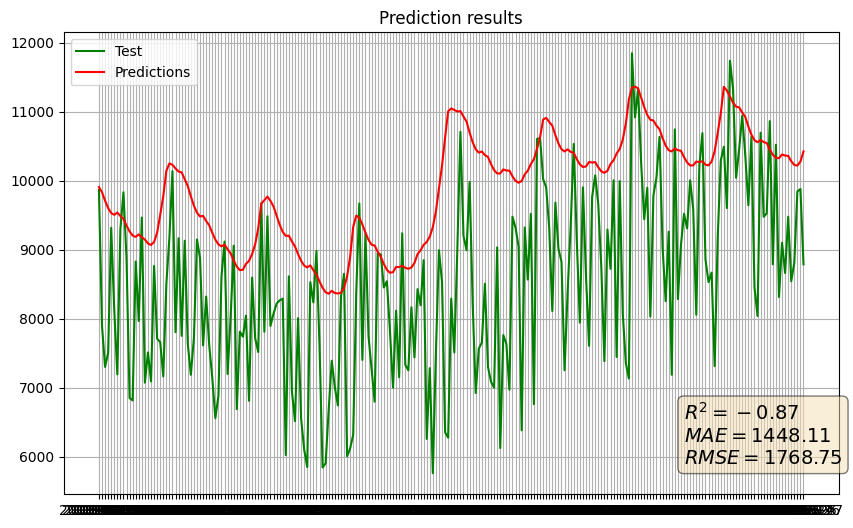

$R^2=-3.61$
$MAE=125.82$
$RMSE=162.93$


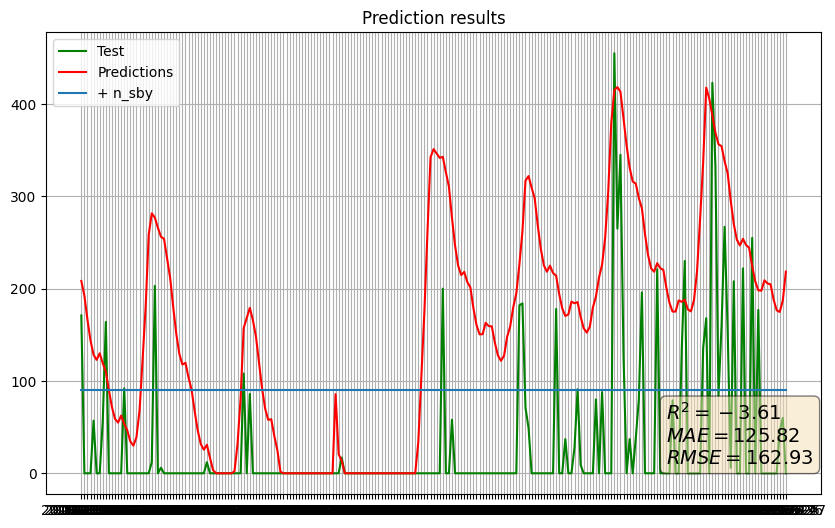

{'Anteil an Tagen mit Unterbesetzung (%)': 3.0303030303030303,
 'Anteil an Tagen mit Überbesetzung (%)': 76.62337662337663,
 'Anteil an Tagen mit perfekter Prediction (%)': 20.346320346320347,
 'Durchschnittliche Überbesetzung': 162.82991519033334,
 'Durchschnittliche Unterbesetzung': 34.81920663201712,
 'Median Überbesetzung': 166.42771944086599,
 'Median Unterbesetzung': 38.5498790335148,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 154.6413876288523,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 123.71065169811637}

In [42]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, root_mean_squared_error
import matplotlib.pyplot as plt

def plot_regression_predictions(y_true: pd.DataFrame, y_pred: pd.DataFrame, y_train: pd.DataFrame = None, annotation : str = "", additional_column_df : pd.DataFrame = None) -> None:
    
    # Metrics
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)

    mape = mean_absolute_percentage_error(y_true, y_pred)

    # Plot 
    plt.figure(figsize=(10, 6))
    plt.title(f'Prediction results' + (f" ({annotation})" if annotation else ""))

    if y_train is not None:
        plt.plot(y_train.index, y_train, label='Train', color='blue')

    plt.plot(y_true.index, y_true, label='Test', color='green')
    plt.plot(y_true.index, y_pred, label='Predictions', color='red')

    if additional_column_df is not None:

        max_value = max([
        y_true.select_dtypes(include=[float, int]).max().max(),
        y_pred.select_dtypes(include=[float, int]).max().max(),
        additional_column_df.select_dtypes(include=[float, int]).max().max(),
        ])

        for column in additional_column_df.columns:
            if additional_column_df[column].dtype == bool:
                plt.plot(additional_column_df.index, additional_column_df[column].astype(int) * max_value, label =  "+ " +column + " (bool)", linestyle="dotted")
            else:
                plt.plot(additional_column_df.index, additional_column_df[column], label = "+ " + column)

    props = dict(boxstyle='round', facecolor='wheat', alpha=0.5)

    textstr = '\n'.join((
        r'$R^2=%.2f$' % (r2, ),
        r'$MAE=%.2f$' % (mae, ),
        r'$RMSE=%.2f$' % (rmse, )))

    print(textstr)

    plt.text(0.8, 0.2, textstr, transform=plt.gca().transAxes, fontsize=14,
        verticalalignment='top', bbox=props)

    plt.legend()
    plt.grid()
    plt.show()

####

plot_regression_predictions(result_df[[target_column_name]], result_df[["predicted_" + target_column_name]])

if target_column_name == "calls":
    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]])
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

## Customize best models

### Gradient Boosting (not working as expected)

,n_duty,sby_need,n_sby,calls,predicted_calls,sby_need_calc
date,,,,,,
2018-10-09,1900,171.0,90,9870.0,9130.401726,42.638665
2018-10-10,1900,0.0,90,7896.0,8851.080360,0.000000
2018-10-11,1900,0.0,90,7302.0,8734.946191,0.000000
2018-10-12,1900,0.0,90,7506.0,8451.368894,0.000000
2018-10-13,1900,57.0,90,9318.0,8313.449347,0.000000
...,...,...,...,...,...,...
2019-05-23,2000,0.0,90,8544.0,8424.434244,0.000000
2019-05-24,2000,0.0,90,8814.0,8245.931005,0.000000
2019-05-25,2000,46.0,90,9846.0,7887.996882,0.000000


$R^2=0.16$
$MAE=978.36$
$RMSE=1188.75$


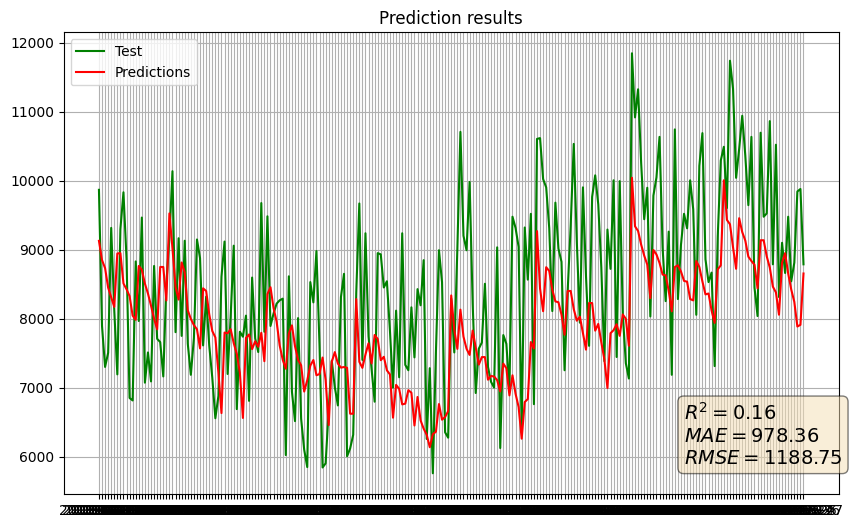

$R^2=-0.06$
$MAE=29.92$
$RMSE=78.03$


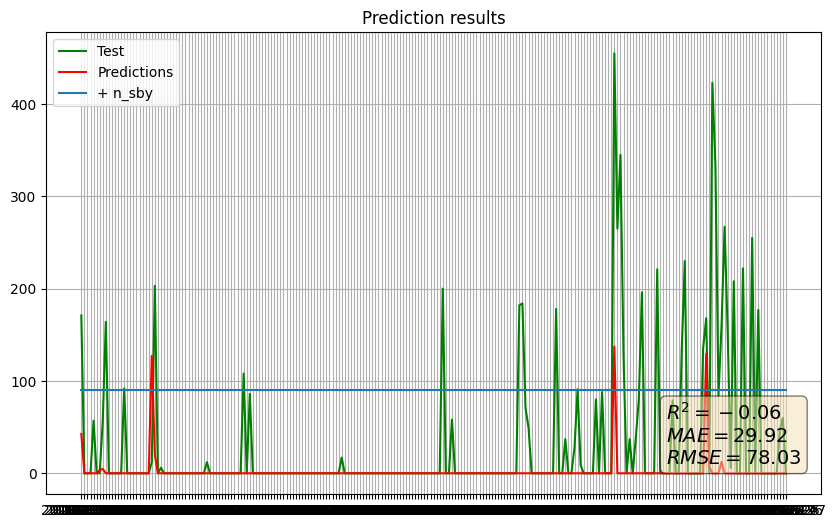

{'Anteil an Tagen mit Unterbesetzung (%)': 22.07792207792208,
 'Anteil an Tagen mit Überbesetzung (%)': 1.2987012987012987,
 'Anteil an Tagen mit perfekter Prediction (%)': 76.62337662337663,
 'Durchschnittliche Überbesetzung': 41.99059113403958,
 'Durchschnittliche Unterbesetzung': 133.07159717210945,
 'Median Überbesetzung': 7.257679709563945,
 'Median Unterbesetzung': 108.0,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 2.096624751621372,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': -28.834111179114558}

In [43]:
import numpy as np
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor

class CustomGradientBoostingRegressor(GradientBoostingRegressor):
    def __init__(self, underestimation_penalty=5, overestimation_penalty=1, n_estimators=100, learning_rate=0.1, max_depth=3, **kwargs):
        self.underestimation_penalty = underestimation_penalty
        self.overestimation_penalty = overestimation_penalty
        super().__init__(n_estimators=n_estimators, learning_rate=learning_rate, max_depth=max_depth, **kwargs)

    def fit(self, X, y, sample_weight=None):
        # Initial fit to get initial predictions
        super().fit(X, y, sample_weight)
        y_pred = self.predict(X)
        
        # Custom boosting iterations
        for i in range(self.n_estimators):
            residual = self.custom_loss(y, y_pred, self.underestimation_penalty, self.overestimation_penalty)
            tree = DecisionTreeRegressor(max_depth=self.max_depth, random_state=self.random_state)
            tree.fit(X, residual, sample_weight=sample_weight)
            y_pred += self.learning_rate * tree.predict(X)
        
        return self

    # Definiere die benutzerdefinierte Verlustfunktion mit variabler Bestrafung
    def custom_loss(self, y_true, y_pred, underestimation_penalty, overestimation_penalty):
        residual = y_true - y_pred
        return np.where(residual < 0, -underestimation_penalty * residual, -overestimation_penalty * residual)

# Initialisiere das Modell mit der benutzerdefinierten Verlustfunktion
model = CustomGradientBoostingRegressor(underestimation_penalty=1, overestimation_penalty=1, random_state=42)

# Trainiere das Modell
model.fit(X_train, y_train)

y_pred = model.predict(X_test)


####

result_df = create_result_df(y_test, y_pred, df, target_column_name)

display(result_df)


plot_regression_predictions(result_df[[target_column_name]], result_df[["predicted_" + target_column_name]])

if target_column_name == "calls":
    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]])
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

### LightGBM

[LightGBM] [Warning] Using self-defined objective function
[LightGBM] [Warning] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000087 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 298
[LightGBM] [Info] Number of data points in the train set: 921, number of used features: 4
[LightGBM] [Warning] Using self-defined objective function


,n_duty,sby_need,n_sby,calls,predicted_calls,sby_need_calc
date,,,,,,
2018-10-09,1900,171.0,90,9870.0,9678.864472,159.332866
2018-10-10,1900,0.0,90,7896.0,9223.781704,62.506745
2018-10-11,1900,0.0,90,7302.0,8954.855833,5.288475
2018-10-12,1900,0.0,90,7506.0,8901.357809,0.000000
2018-10-13,1900,57.0,90,9318.0,8421.597444,0.000000
...,...,...,...,...,...,...
2019-05-23,2000,0.0,90,8544.0,9334.319543,0.000000
2019-05-24,2000,0.0,90,8814.0,8920.898076,0.000000
2019-05-25,2000,46.0,90,9846.0,8808.310587,0.000000


$R^2=0.42$
$MAE=842.58$
$RMSE=986.82$


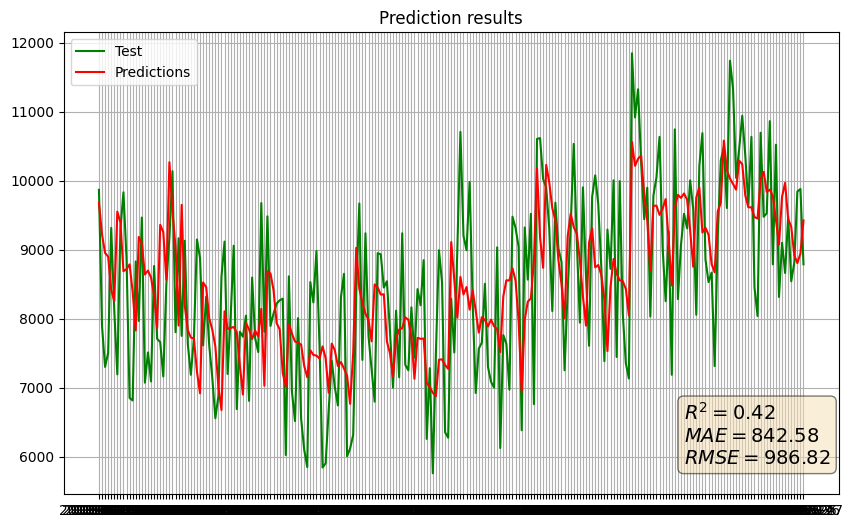

$R^2=0.28$
$MAE=30.72$
$RMSE=64.31$


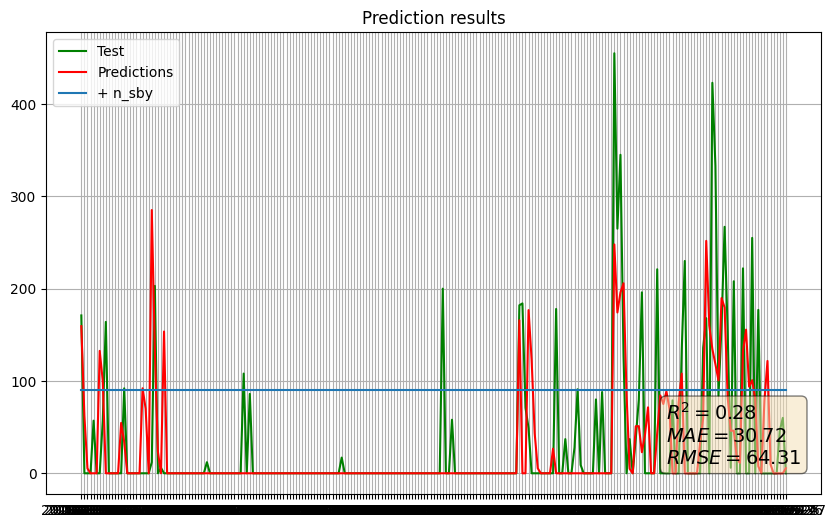

{'Anteil an Tagen mit Unterbesetzung (%)': 18.614718614718615,
 'Anteil an Tagen mit Überbesetzung (%)': 17.316017316017316,
 'Anteil an Tagen mit perfekter Prediction (%)': 64.06926406926407,
 'Durchschnittliche Überbesetzung': 71.40179871461416,
 'Durchschnittliche Unterbesetzung': 98.63289178730865,
 'Median Überbesetzung': 70.65887572448935,
 'Median Unterbesetzung': 80.0,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 24.934448492338937,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': -5.996287438396994}

In [44]:
import lightgbm as lgb
import numpy as np


# Definiere deine benutzerdefinierte Bewertungsmetrik
def custom_loss(y_pred, dataset):

    underestimation_penalty = 100
    overestimation_penalty = 1

    y_true = dataset.get_label()
    residual = (y_true - y_pred).astype("float")
    grad = np.where(residual > 0, -underestimation_penalty * residual, -overestimation_penalty * residual)  # Gradientenberechnung
    hess = np.where(residual > 0, underestimation_penalty, overestimation_penalty)  # Hesse-Matrix
    return grad, hess



# Erstelle das Dataset für LightGBM
train_data = lgb.Dataset(X_train, label=y_train)
valid_data = lgb.Dataset(X_test, label=y_test, reference=train_data)

# Definiere die Parameter
params = {
    'objective': 'regression',
    'metric': 'custom'
}

# Trainiere das Modell
bst = lgb.train(params, train_data, fobj=custom_loss, valid_sets=[train_data]) # für fobj LightGBM gedwongraded auf Version 3.2.1

# Vorhersagen machen
y_pred_best = bst.predict(X_test)

####

result_df = create_result_df(y_test, y_pred_best, df, target_column_name)

display(result_df)

plot_regression_predictions(result_df[[target_column_name]], result_df[["predicted_" + target_column_name]])

if target_column_name == "calls":
    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]])
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

### LSTM

Epoch 1/100


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - loss: 0.5674 - val_loss: 0.0686
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0853 - val_loss: 0.0431
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0699 - val_loss: 0.0448
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0625 - val_loss: 0.0479
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0562 - val_loss: 0.0899
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0542 - val_loss: 0.0496
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0497 - val_loss: 0.0370
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0543 - val_loss: 0.0568
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 0.0477 - val_loss: 0.0443
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0499 - val_loss: 0.0614
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0550 - val_loss: 0.0496
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0

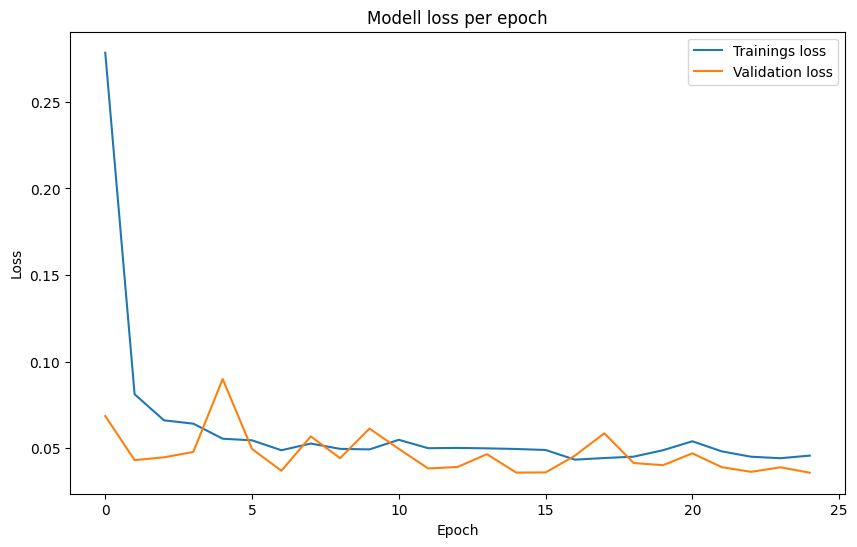

In [45]:
from app.sklearn_keras_wrapper import LSTMModelWrapper

lstm_model = LSTMModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=10)
lstm_model.fit(X_train, y_train, epochs=100)
#lstm_model = LSTMModelWrapper.load("lstm_model")

predictions = lstm_model.predict(X_test)
score = lstm_model.score(X_test, y_test)
lstm_model.plot_loss()

,n_duty,sby_need,n_sby,calls,predicted_calls,sby_need_calc
date,,,,,,
2018-10-09,1900,171.0,90,9870.0,9629.390419,148.806472
2018-10-10,1900,0.0,90,7896.0,9636.884193,150.400892
2018-10-11,1900,0.0,90,7302.0,9468.716103,114.620447
2018-10-12,1900,0.0,90,7506.0,9336.959267,86.587078
2018-10-13,1900,57.0,90,9318.0,9264.714272,71.215802
...,...,...,...,...,...,...
2019-05-23,2000,0.0,90,8544.0,9975.576096,122.462999
2019-05-24,2000,0.0,90,8814.0,9851.655281,96.096868
2019-05-25,2000,46.0,90,9846.0,9793.775963,83.782120


$R^2=-0.29$
$MAE=1172.02$
$RMSE=1468.36$


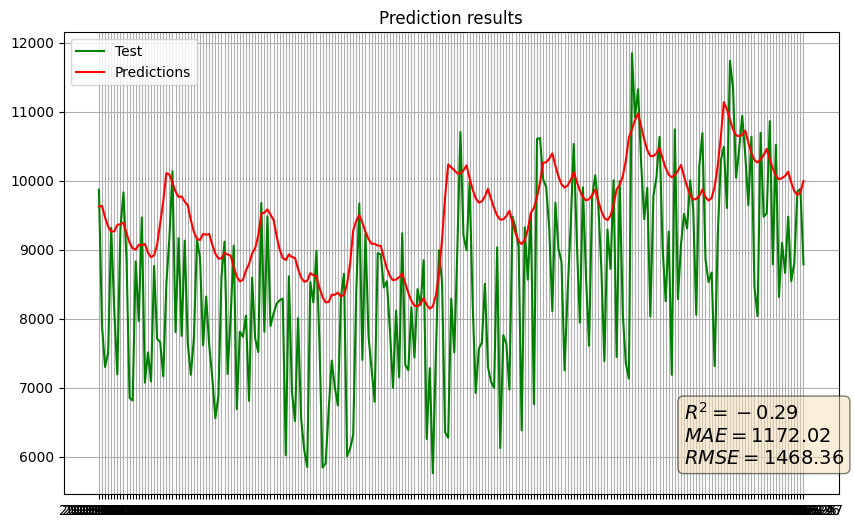

$R^2=-0.72$
$MAE=68.35$
$RMSE=99.60$


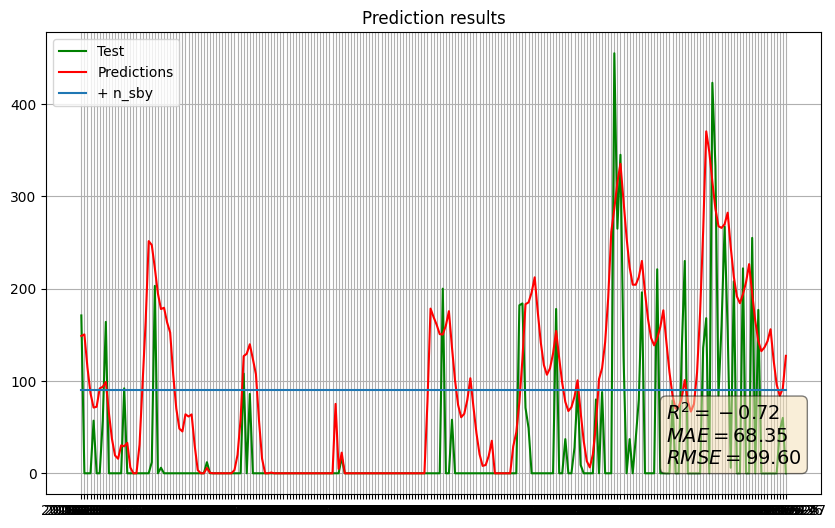

{'Anteil an Tagen mit Unterbesetzung (%)': 8.225108225108226,
 'Anteil an Tagen mit Überbesetzung (%)': 63.20346320346321,
 'Anteil an Tagen mit perfekter Prediction (%)': 28.57142857142857,
 'Durchschnittliche Überbesetzung': 100.3996350547725,
 'Durchschnittliche Unterbesetzung': 59.52262791273711,
 'Median Überbesetzung': 96.41817295804924,
 'Median Unterbesetzung': 51.43111890427599,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 89.4909817647393,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 58.56024583400337}

In [46]:
result_df = create_result_df(y_test, predictions, df, target_column_name)

display(result_df)


plot_regression_predictions(result_df[[target_column_name]], result_df[["predicted_" + target_column_name]])

if target_column_name == "calls":
    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]])
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

In [47]:
lstm_model.save("../../app/models/lstm")

### GRU

Epoch 1/100


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step - loss: 3.2153 - val_loss: 0.2711
Epoch 2/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.2914 - val_loss: 0.1564
Epoch 3/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1932 - val_loss: 0.0930
Epoch 4/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1518 - val_loss: 0.0702
Epoch 5/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1165 - val_loss: 0.0645
Epoch 6/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.1128 - val_loss: 0.0655
Epoch 7/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0867 - val_loss: 0.0607
Epoch 8/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0930 - val_loss: 0.1222
Epoch 9/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0858 - val_loss: 0.1371
Epoch 10/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0976 - val_loss: 0.3026
Epoch 11/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.1019 - val_loss: 0.0682
Epoch 12/100
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0

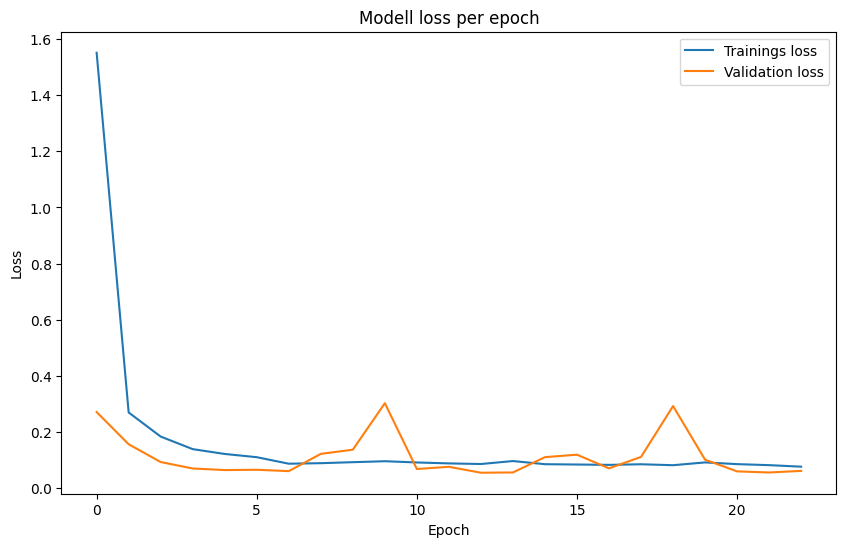

In [48]:
from app.sklearn_keras_wrapper import GRUModelWrapper

gru_model = GRUModelWrapper(historical_data_for_sequence=X_train[-30:], regularization_for_underestimation=50)
gru_model.fit(X_train, y_train, epochs=100)
#gru_model = GRUModelWrapper.load("gru")

predictions = gru_model.predict(X_test)
score = gru_model.score(X_test, y_test)
gru_model.plot_loss()

,n_duty,sby_need,n_sby,calls,predicted_calls,sby_need_calc
date,,,,,,
2018-10-09,1900,171.0,90,9870.0,9916.282997,209.847446
2018-10-10,1900,0.0,90,7896.0,9785.249794,181.968041
2018-10-11,1900,0.0,90,7302.0,9509.663979,123.332761
2018-10-12,1900,0.0,90,7506.0,9300.150970,78.755526
2018-10-13,1900,57.0,90,9318.0,9214.020836,60.429965
...,...,...,...,...,...,...
2019-05-23,2000,0.0,90,8544.0,9980.657616,123.544174
2019-05-24,2000,0.0,90,8814.0,9745.986626,73.614176
2019-05-25,2000,46.0,90,9846.0,9635.258194,50.054935


$R^2=-0.81$
$MAE=1416.02$
$RMSE=1743.21$


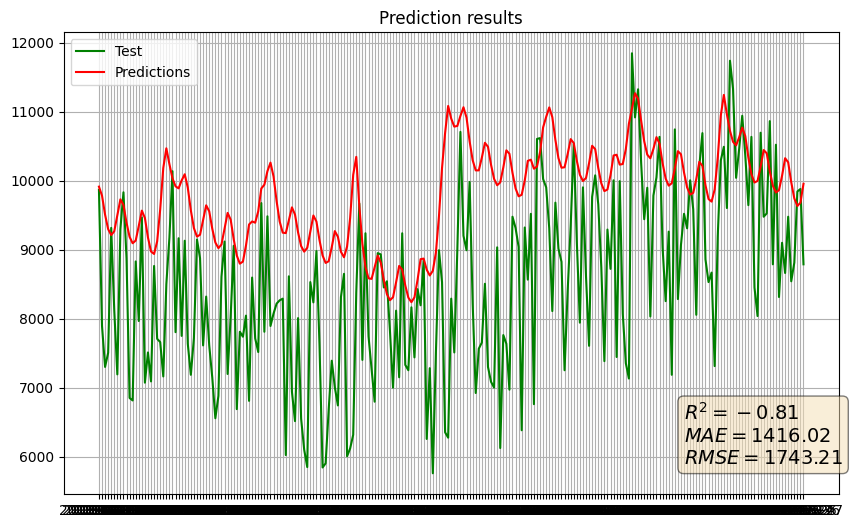

$R^2=-2.78$
$MAE=116.96$
$RMSE=147.48$


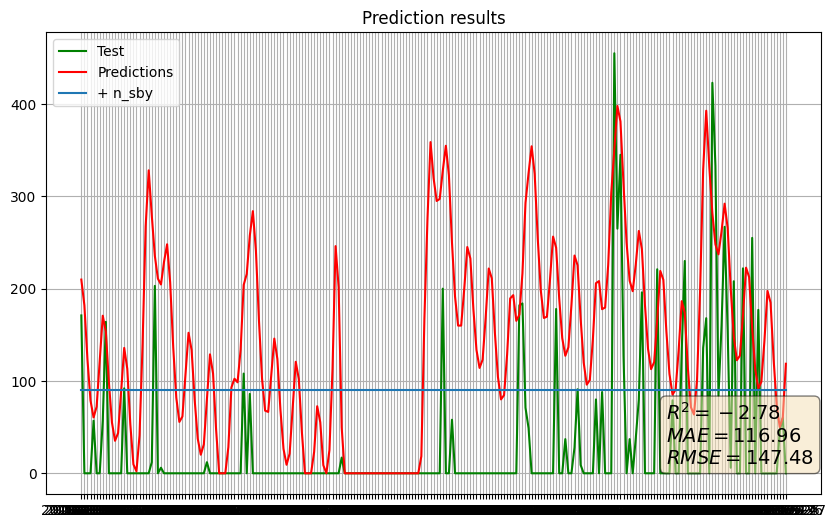

{'Anteil an Tagen mit Unterbesetzung (%)': 4.761904761904762,
 'Anteil an Tagen mit Überbesetzung (%)': 81.38528138528139,
 'Anteil an Tagen mit perfekter Prediction (%)': 13.852813852813853,
 'Durchschnittliche Überbesetzung': 139.68723612276332,
 'Durchschnittliche Unterbesetzung': 68.74010908765075,
 'Median Überbesetzung': 128.27431212080273,
 'Median Unterbesetzung': 60.014713693172325,
 'Tagesdurchschnitt Ersatzfahrer für Planung': 141.3422475805859,
 'Differenz Tagesdurchschnitt Ersatzfahrer zu Realität': 110.41151164984997}

In [49]:
result_df = create_result_df(y_test, predictions, df, target_column_name)

display(result_df)


plot_regression_predictions(result_df[[target_column_name]], result_df[["predicted_" + target_column_name]])

if target_column_name == "calls":
    plot_regression_predictions(result_df[["sby_need"]], result_df[["sby_need_calc"]], additional_column_df=result_df[["n_sby"]])
    display(calculate_custom_personal_metrics(result_df, "sby_need", "sby_need_calc"))

In [50]:
lstm_model.save("../../app/models/gru")